# Wine Quality — Exploratory Data Analysis (EDA)

## Submitted By
**Name:** MK NANDANA
---

## Project Description

This project performs an Exploratory Data Analysis (EDA) on the UCI Wine Quality Dataset. The objective is to understand the physicochemical characteristics of Portuguese Vinho Verde red and white wines and investigate how these properties relate to wine quality. The analysis includes data loading, preprocessing, visualization, comparative analysis, correlation analysis, statistical testing, outlier detection, and feature engineering.

# 1. Dataset Research and Background

## Wine Quality Dataset

The Wine Quality dataset is one of the most widely used datasets for machine learning and exploratory data analysis. It was created to study the relationship between physicochemical properties of Portuguese "Vinho Verde" wines and their sensory quality.

The dataset was introduced by:

**Cortez, P., Cerdeira, A., Almeida, F., Matos, T., & Reis, J. (2009).**

*Modeling Wine Preferences by Data Mining from Physicochemical Properties.*

Published in **Decision Support Systems.**

---

## Dataset Source

UCI Machine Learning Repository

Dataset ID: 186

https://archive.ics.uci.edu/ml/datasets/wine+quality

---

## Dataset Overview

| Characteristic | Details |
|---------------|---------|
| Red wine observations | 1599 |
| White wine observations | 4898 |
| Combined observations | 6497 |
| Physicochemical features | 11 |
| Target feature | Quality |
| Total columns | 12 |
| Missing values | None reported |
| Dataset type | Multivariate numerical |
| Associated tasks | Regression & Classification |
| Quality Score | Ordinal (0–10) |

# Import Required Libraries

In [ ]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import pearsonr
from scipy.stats import spearmanr
from scipy.stats import zscore
from scipy.stats import ttest_ind
from scipy.stats import mannwhitneyu

plt.style.use("ggplot")

%matplotlib inline

# Load the Dataset

In [ ]:
red_url = "https://raw.githubusercontent.com/WangLaoShi/Datasets/main/UCI-Wine-Quality-Data-Set/winequality-red.csv"

white_url = "https://raw.githubusercontent.com/WangLaoShi/Datasets/main/UCI-Wine-Quality-Data-Set/winequality-white.csv"

red = pd.read_csv(red_url, sep=";")
white = pd.read_csv(white_url, sep=";")

In [ ]:
print("Red Wine Dataset")
display(red.head())

print("White Wine Dataset")
display(white.head())

Red Wine Dataset


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


White Wine Dataset


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.0,0.27,0.36,20.7,0.045,45.0,170.0,1.0010,3.00,0.45,8.8,6
1,6.3,0.30,0.34,1.6,0.049,14.0,132.0,0.9940,3.30,0.49,9.5,6
2,8.1,0.28,0.40,6.9,0.050,30.0,97.0,0.9951,3.26,0.44,10.1,6
3,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6
4,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6


# Section A – Data Loading, Inspection and Preprocessing

## Question 1

**Load `winequality-red.csv` and `winequality-white.csv` into separate Pandas DataFrames. Display the first 10 and last 10 records of each dataset.**

**Suggested Output:** Display tables.

**Suggested Visualization:** None.

### Purpose
This step verifies that both datasets have been loaded correctly and allows us to inspect the structure of the data before performing any analysis.

In [ ]:
print("="*70)
print("RED WINE DATASET - FIRST 10 RECORDS")
print("="*70)

display(red.head(10))

print("="*70)
print("RED WINE DATASET - LAST 10 RECORDS")
print("="*70)

display(red.tail(10))

RED WINE DATASET - FIRST 10 RECORDS


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
5,7.4,0.66,0.00,1.8,0.075,13.0,40.0,0.9978,3.51,0.56,9.4,5
6,7.9,0.60,0.06,1.6,0.069,15.0,59.0,0.9964,3.30,0.46,9.4,5
7,7.3,0.65,0.00,1.2,0.065,15.0,21.0,0.9946,3.39,0.47,10.0,7
8,7.8,0.58,0.02,2.0,0.073,9.0,18.0,0.9968,3.36,0.57,9.5,7
9,7.5,0.50,0.36,6.1,0.071,17.0,102.0,0.9978,3.35,0.80,10.5,5


RED WINE DATASET - LAST 10 RECORDS


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
1589,6.6,0.725,0.20,7.8,0.073,29.0,79.0,0.99770,3.29,0.54,9.2,5
1590,6.3,0.550,0.15,1.8,0.077,26.0,35.0,0.99314,3.32,0.82,11.6,6
1591,5.4,0.740,0.09,1.7,0.089,16.0,26.0,0.99402,3.67,0.56,11.6,6
1592,6.3,0.510,0.13,2.3,0.076,29.0,40.0,0.99574,3.42,0.75,11.0,6
1593,6.8,0.620,0.08,1.9,0.068,28.0,38.0,0.99651,3.42,0.82,9.5,6
1594,6.2,0.600,0.08,2.0,0.090,32.0,44.0,0.99490,3.45,0.58,10.5,5
1595,5.9,0.550,0.10,2.2,0.062,39.0,51.0,0.99512,3.52,0.76,11.2,6
1596,6.3,0.510,0.13,2.3,0.076,29.0,40.0,0.99574,3.42,0.75,11.0,6
1597,5.9,0.645,0.12,2.0,0.075,32.0,44.0,0.99547,3.57,0.71,10.2,5
1598,6.0,0.310,0.47,3.6,0.067,18.0,42.0,0.99549,3.39,0.66,11.0,6


In [ ]:
print("="*70)
print("WHITE WINE DATASET - FIRST 10 RECORDS")
print("="*70)

display(white.head(10))

print("="*70)
print("WHITE WINE DATASET - LAST 10 RECORDS")
print("="*70)

display(white.tail(10))

WHITE WINE DATASET - FIRST 10 RECORDS


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.0,0.27,0.36,20.7,0.045,45.0,170.0,1.0010,3.00,0.45,8.8,6
1,6.3,0.30,0.34,1.6,0.049,14.0,132.0,0.9940,3.30,0.49,9.5,6
2,8.1,0.28,0.40,6.9,0.050,30.0,97.0,0.9951,3.26,0.44,10.1,6
3,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6
4,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6
5,8.1,0.28,0.40,6.9,0.050,30.0,97.0,0.9951,3.26,0.44,10.1,6
6,6.2,0.32,0.16,7.0,0.045,30.0,136.0,0.9949,3.18,0.47,9.6,6
7,7.0,0.27,0.36,20.7,0.045,45.0,170.0,1.0010,3.00,0.45,8.8,6
8,6.3,0.30,0.34,1.6,0.049,14.0,132.0,0.9940,3.30,0.49,9.5,6
9,8.1,0.22,0.43,1.5,0.044,28.0,129.0,0.9938,3.22,0.45,11.0,6


WHITE WINE DATASET - LAST 10 RECORDS


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
4888,6.8,0.220,0.36,1.20,0.052,38.0,127.0,0.99330,3.04,0.54,9.2,5
4889,4.9,0.235,0.27,11.75,0.030,34.0,118.0,0.99540,3.07,0.50,9.4,6
4890,6.1,0.340,0.29,2.20,0.036,25.0,100.0,0.98938,3.06,0.44,11.8,6
4891,5.7,0.210,0.32,0.90,0.038,38.0,121.0,0.99074,3.24,0.46,10.6,6
4892,6.5,0.230,0.38,1.30,0.032,29.0,112.0,0.99298,3.29,0.54,9.7,5
4893,6.2,0.210,0.29,1.60,0.039,24.0,92.0,0.99114,3.27,0.50,11.2,6
4894,6.6,0.320,0.36,8.00,0.047,57.0,168.0,0.99490,3.15,0.46,9.6,5
4895,6.5,0.240,0.19,1.20,0.041,30.0,111.0,0.99254,2.99,0.46,9.4,6
4896,5.5,0.290,0.30,1.10,0.022,20.0,110.0,0.98869,3.34,0.38,12.8,7
4897,6.0,0.210,0.38,0.80,0.020,22.0,98.0,0.98941,3.26,0.32,11.8,6


### Observation

- Both datasets were successfully loaded into separate Pandas DataFrames.
- The first and last 10 records were displayed for verification.
- Each dataset contains physicochemical properties of wine samples along with their corresponding quality scores.
- No issues were observed while loading the datasets.

## Question 2

**Determine the dimensions (rows and columns) of each dataset. List all feature names, their data types, and identify the memory usage. Discuss whether all features are numerical and suitable for statistical analysis.**

**Suggested Output:** Shape, columns, dtypes, memory usage.

**Suggested Visualization:** None.

### Purpose
Understanding the dimensions, feature names, data types, and memory usage helps in assessing the dataset before further preprocessing and statistical analysis.

In [ ]:
print("="*60)
print("RED WINE DATASET SHAPE")
print("="*60)
print(red.shape)

print("\n")

print("="*60)
print("WHITE WINE DATASET SHAPE")
print("="*60)
print(white.shape)

RED WINE DATASET SHAPE
(1599, 12)


WHITE WINE DATASET SHAPE
(4898, 12)


In [ ]:
print("="*60)
print("RED WINE COLUMN NAMES")
print("="*60)

print(red.columns.tolist())

print("\n")

print("="*60)
print("WHITE WINE COLUMN NAMES")
print("="*60)

print(white.columns.tolist())

RED WINE COLUMN NAMES
['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol', 'quality']


WHITE WINE COLUMN NAMES
['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol', 'quality']


In [ ]:
print("="*60)
print("RED WINE DATA TYPES")
print("="*60)

print(red.dtypes)

print("\n")

print("="*60)
print("WHITE WINE DATA TYPES")
print("="*60)

print(white.dtypes)

RED WINE DATA TYPES
fixed acidity           float64
volatile acidity        float64
citric acid             float64
residual sugar          float64
chlorides               float64
free sulfur dioxide     float64
total sulfur dioxide    float64
density                 float64
pH                      float64
sulphates               float64
alcohol                 float64
quality                   int64
dtype: object


WHITE WINE DATA TYPES
fixed acidity           float64
volatile acidity        float64
citric acid             float64
residual sugar          float64
chlorides               float64
free sulfur dioxide     float64
total sulfur dioxide    float64
density                 float64
pH                      float64
sulphates               float64
alcohol                 float64
quality                   int64
dtype: object


In [ ]:
print("="*60)
print("RED WINE MEMORY USAGE")
print("="*60)

red.info(memory_usage='deep')

print("\n")

print("="*60)
print("WHITE WINE MEMORY USAGE")
print("="*60)

white.info(memory_usage='deep')

RED WINE MEMORY USAGE
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  quality               1599 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 150.0 KB


WHITE WINE MEMORY USAGE
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4898 entries, 0 to 4897
Data

### Observation

- The Red Wine dataset contains **1599 rows** and **12 columns**.
- The White Wine dataset contains **4898 rows** and **12 columns**.
- Both datasets contain the same set of physicochemical features.
- All predictor variables are numerical (integer or floating-point values).
- The `quality` attribute is an integer representing the wine quality score.
- Since all variables are numerical, the datasets are well suited for statistical analysis, visualization, and machine learning techniques.

##Question 3

In [ ]:
red["wine_type"] = "Red"
white["wine_type"] = "White"

wine = pd.concat([red, white], ignore_index=True)

display(wine.head())
print(wine.shape)

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,wine_type
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,Red
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,Red
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,Red
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,Red
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,Red


(6497, 13)


##Question 4

In [ ]:
print(wine.isnull().sum())

fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
wine_type               0
dtype: int64


##Question 5

In [ ]:
print("Red Duplicates:", red.duplicated().sum())
print("White Duplicates:", white.duplicated().sum())
print("Combined Duplicates:", wine.duplicated().sum())

Red Duplicates: 240
White Duplicates: 937
Combined Duplicates: 1177


##Question 6

In [ ]:
display(red.describe())

display(white.describe())

display(wine.describe())

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000
mean,8.319637,0.527821,0.270976,2.538806,0.087467,15.874922,46.467792,0.996747,3.311113,0.658149,10.422983,5.636023
std,1.741096,0.179060,0.194801,1.409928,0.047065,10.460157,32.895324,0.001887,0.154386,0.169507,1.065668,0.807569
min,4.600000,0.120000,0.000000,0.900000,0.012000,1.000000,6.000000,0.990070,2.740000,0.330000,8.400000,3.000000
25%,7.100000,0.390000,0.090000,1.900000,0.070000,7.000000,22.000000,0.995600,3.210000,0.550000,9.500000,5.000000
50%,7.900000,0.520000,0.260000,2.200000,0.079000,14.000000,38.000000,0.996750,3.310000,0.620000,10.200000,6.000000
75%,9.200000,0.640000,0.420000,2.600000,0.090000,21.000000,62.000000,0.997835,3.400000,0.730000,11.100000,6.000000
max,15.900000,1.580000,1.000000,15.500000,0.611000,72.000000,289.000000,1.003690,4.010000,2.000000,14.900000,8.000000


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,4898.000000,4898.000000,4898.000000,4898.000000,4898.000000,4898.000000,4898.000000,4898.000000,4898.000000,4898.000000,4898.000000,4898.000000
mean,6.854788,0.278241,0.334192,6.391415,0.045772,35.308085,138.360657,0.994027,3.188267,0.489847,10.514267,5.877909
std,0.843868,0.100795,0.121020,5.072058,0.021848,17.007137,42.498065,0.002991,0.151001,0.114126,1.230621,0.885639
min,3.800000,0.080000,0.000000,0.600000,0.009000,2.000000,9.000000,0.987110,2.720000,0.220000,8.000000,3.000000
25%,6.300000,0.210000,0.270000,1.700000,0.036000,23.000000,108.000000,0.991723,3.090000,0.410000,9.500000,5.000000
50%,6.800000,0.260000,0.320000,5.200000,0.043000,34.000000,134.000000,0.993740,3.180000,0.470000,10.400000,6.000000
75%,7.300000,0.320000,0.390000,9.900000,0.050000,46.000000,167.000000,0.996100,3.280000,0.550000,11.400000,6.000000
max,14.200000,1.100000,1.660000,65.800000,0.346000,289.000000,440.000000,1.038980,3.820000,1.080000,14.200000,9.000000


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000
mean,7.215307,0.339666,0.318633,5.443235,0.056034,30.525319,115.744574,0.994697,3.218501,0.531268,10.491801,5.818378
std,1.296434,0.164636,0.145318,4.757804,0.035034,17.749400,56.521855,0.002999,0.160787,0.148806,1.192712,0.873255
min,3.800000,0.080000,0.000000,0.600000,0.009000,1.000000,6.000000,0.987110,2.720000,0.220000,8.000000,3.000000
25%,6.400000,0.230000,0.250000,1.800000,0.038000,17.000000,77.000000,0.992340,3.110000,0.430000,9.500000,5.000000
50%,7.000000,0.290000,0.310000,3.000000,0.047000,29.000000,118.000000,0.994890,3.210000,0.510000,10.300000,6.000000
75%,7.700000,0.400000,0.390000,8.100000,0.065000,41.000000,156.000000,0.996990,3.320000,0.600000,11.300000,6.000000
max,15.900000,1.580000,1.660000,65.800000,0.611000,289.000000,440.000000,1.038980,4.010000,2.000000,14.900000,9.000000


#Section B

##Question 7

In [ ]:
print("Red Wine Quality Distribution")
print(red["quality"].value_counts().sort_index())

print("\nWhite Wine Quality Distribution")
print(white["quality"].value_counts().sort_index())

Red Wine Quality Distribution
quality
3     10
4     53
5    681
6    638
7    199
8     18
Name: count, dtype: int64

White Wine Quality Distribution
quality
3      20
4     163
5    1457
6    2198
7     880
8     175
9       5
Name: count, dtype: int64


##Question 8

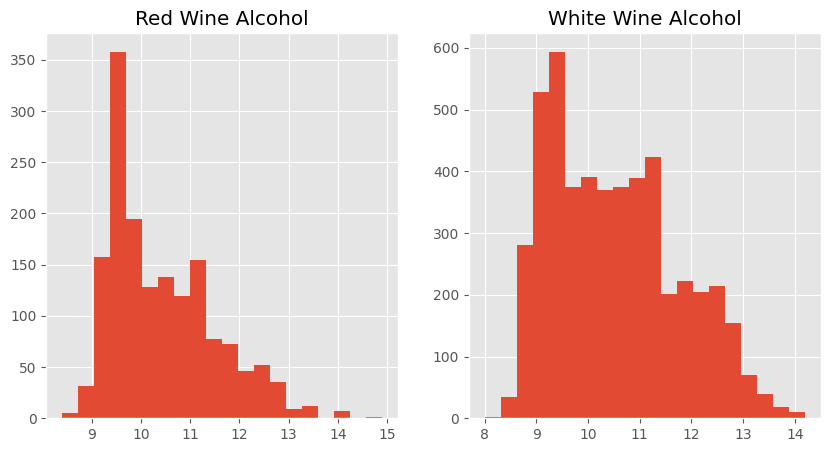

In [ ]:
plt.figure(figsize=(10,5))

plt.subplot(1,2,1)
plt.hist(red["alcohol"], bins=20)
plt.title("Red Wine Alcohol")

plt.subplot(1,2,2)
plt.hist(white["alcohol"], bins=20)
plt.title("White Wine Alcohol")

plt.show()

##Question 9

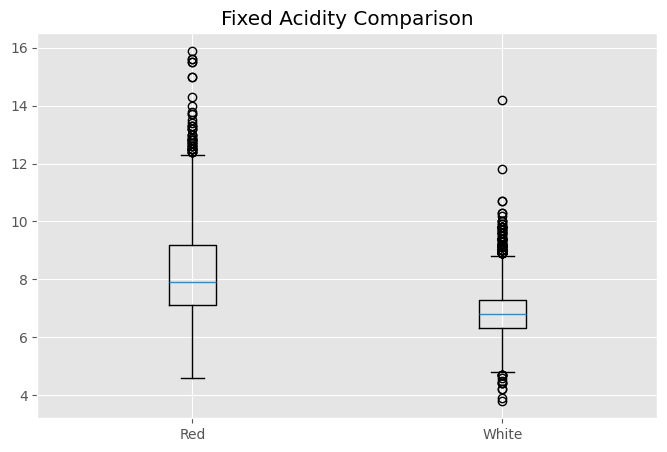

In [ ]:
plt.figure(figsize=(8,5))

plt.boxplot([red["fixed acidity"], white["fixed acidity"]],
            labels=["Red","White"])

plt.title("Fixed Acidity Comparison")

plt.show()

##Qustion 10

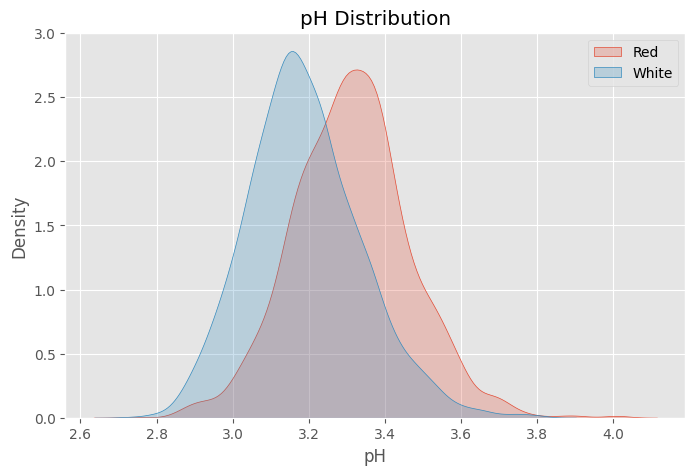

In [ ]:
plt.figure(figsize=(8,5))

sns.kdeplot(red["pH"], label="Red", fill=True)
sns.kdeplot(white["pH"], label="White", fill=True)

plt.title("pH Distribution")
plt.legend()

plt.show()

##Question 11

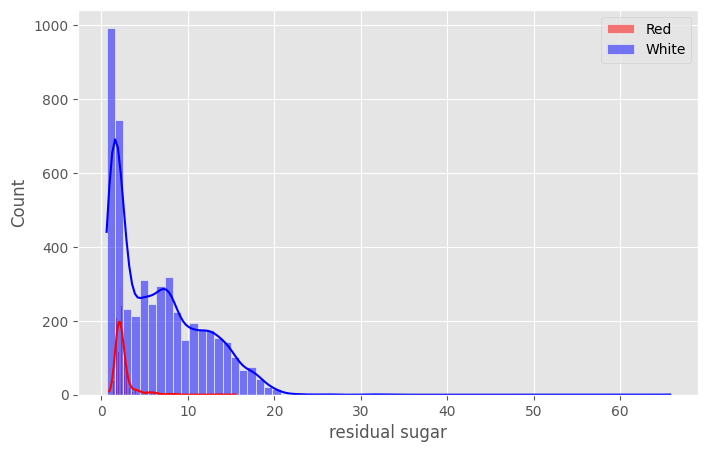

In [ ]:
plt.figure(figsize=(8,5))

sns.histplot(red["residual sugar"], color="red", label="Red", kde=True)

sns.histplot(white["residual sugar"], color="blue", label="White", kde=True)

plt.legend()

plt.show()

##Question 12

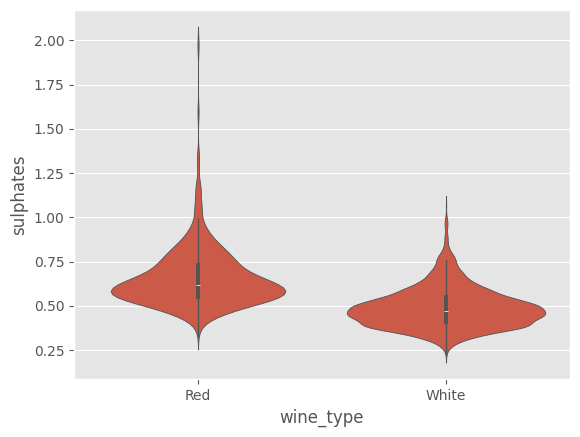

In [ ]:
red["wine_type"]="Red"
white["wine_type"]="White"

wine = pd.concat([red, white])

sns.violinplot(x="wine_type",
               y="sulphates",
               data=wine)

plt.show()

#SECTION C

##Question 13

In [ ]:
mean_red = red.mean(numeric_only=True)
mean_white = white.mean(numeric_only=True)

comparison = pd.DataFrame({
    "Red Wine": mean_red,
    "White Wine": mean_white
})

display(comparison)

,Red Wine,White Wine
fixed acidity,8.319637,6.854788
volatile acidity,0.527821,0.278241
citric acid,0.270976,0.334192
residual sugar,2.538806,6.391415
chlorides,0.087467,0.045772
free sulfur dioxide,15.874922,35.308085
total sulfur dioxide,46.467792,138.360657
density,0.996747,0.994027
pH,3.311113,3.188267
sulphates,0.658149,0.489847


##Question 14

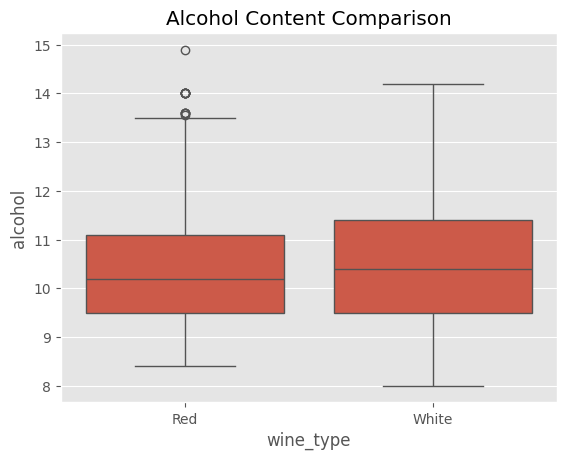

In [ ]:
red["wine_type"] = "Red"
white["wine_type"] = "White"

wine = pd.concat([red, white], ignore_index=True)

sns.boxplot(x="wine_type", y="alcohol", data=wine)
plt.title("Alcohol Content Comparison")
plt.show()

##Question 15

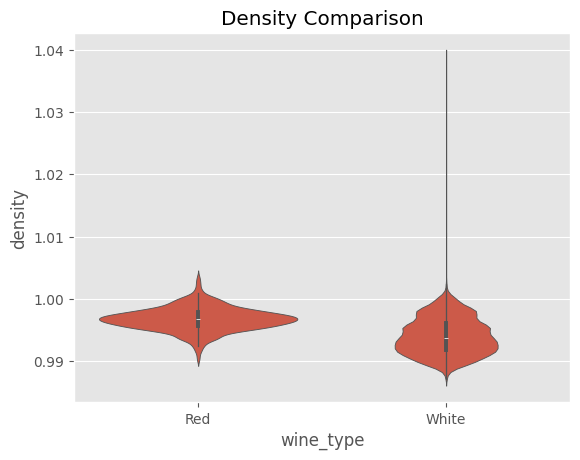

In [ ]:
sns.violinplot(x="wine_type", y="density", data=wine)
plt.title("Density Comparison")
plt.show()

##Question 16

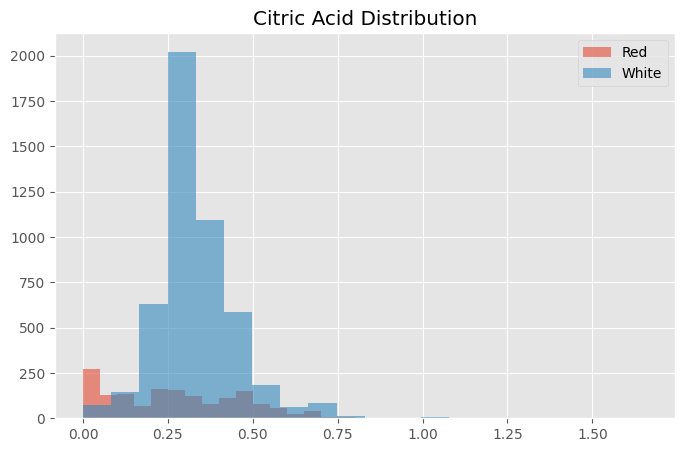

In [ ]:
plt.figure(figsize=(8,5))

plt.hist(red["citric acid"], bins=20, alpha=0.6, label="Red")
plt.hist(white["citric acid"], bins=20, alpha=0.6, label="White")

plt.legend()
plt.title("Citric Acid Distribution")
plt.show()

##Question 17

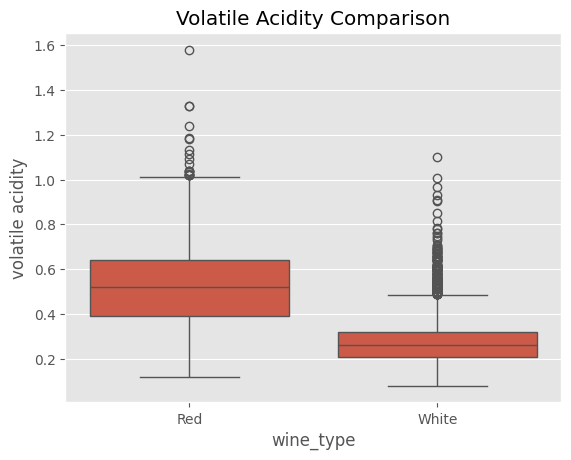

In [ ]:
sns.boxplot(x="wine_type", y="volatile acidity", data=wine)
plt.title("Volatile Acidity Comparison")
plt.show()

##Question 18

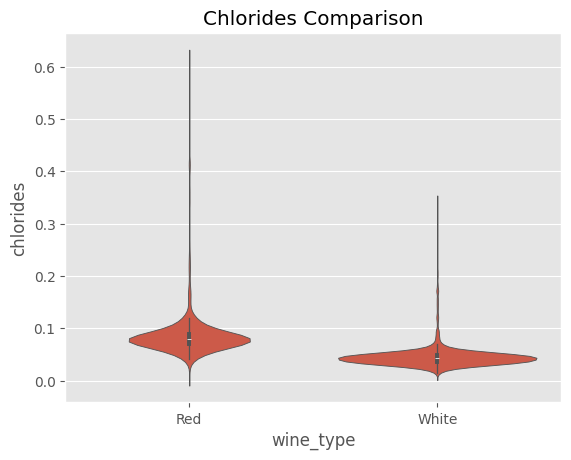

In [ ]:
sns.violinplot(x="wine_type", y="chlorides", data=wine)
plt.title("Chlorides Comparison")
plt.show()

##Question 19

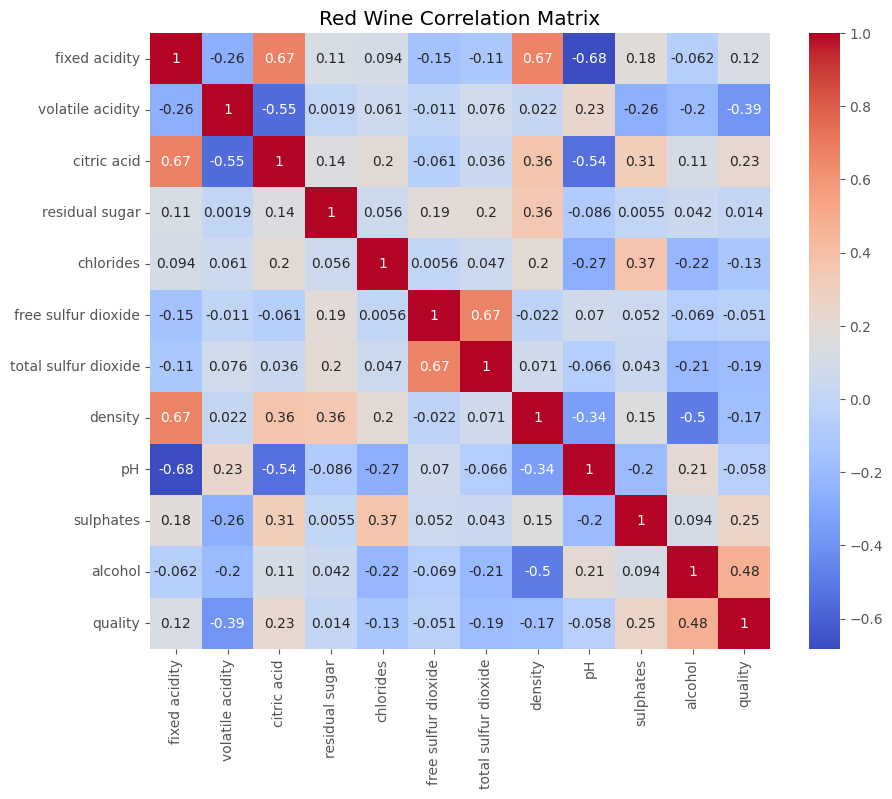

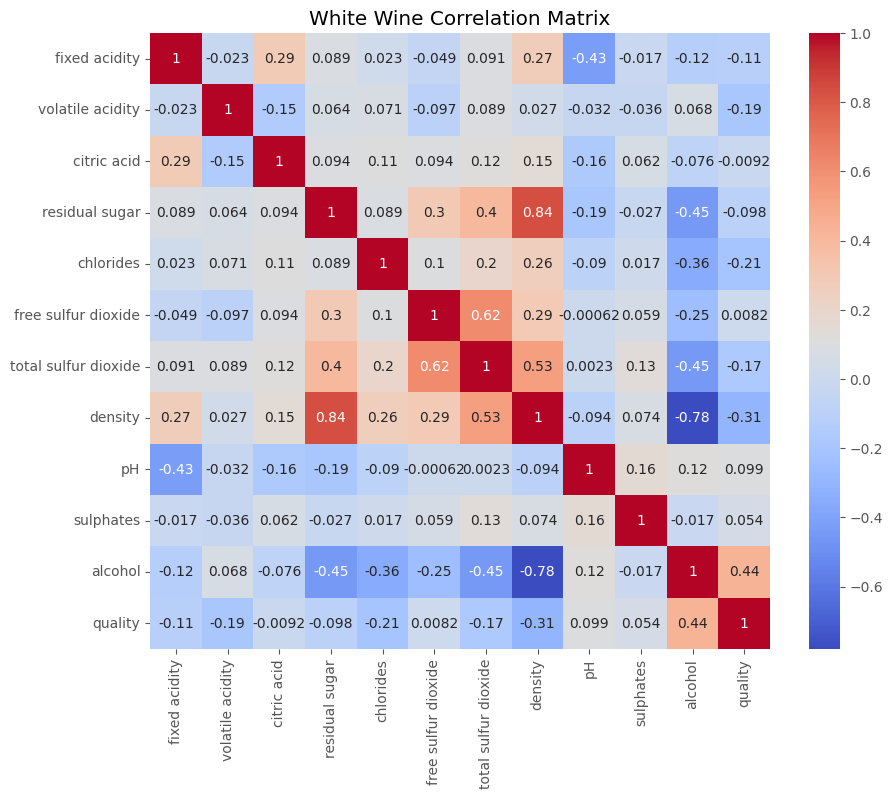

In [ ]:
plt.figure(figsize=(10,8))
sns.heatmap(red.corr(numeric_only=True), annot=True, cmap="coolwarm")
plt.title("Red Wine Correlation Matrix")
plt.show()

plt.figure(figsize=(10,8))
sns.heatmap(white.corr(numeric_only=True), annot=True, cmap="coolwarm")
plt.title("White Wine Correlation Matrix")
plt.show()

##Question 20

In [ ]:
print("Red Wine Correlation with Quality")
print(red.corr(numeric_only=True)["quality"].sort_values())

print("\nWhite Wine Correlation with Quality")
print(white.corr(numeric_only=True)["quality"].sort_values())

Red Wine Correlation with Quality
volatile acidity       -0.390558
total sulfur dioxide   -0.185100
density                -0.174919
chlorides              -0.128907
pH                     -0.057731
free sulfur dioxide    -0.050656
residual sugar          0.013732
fixed acidity           0.124052
citric acid             0.226373
sulphates               0.251397
alcohol                 0.476166
quality                 1.000000
Name: quality, dtype: float64

White Wine Correlation with Quality
density                -0.307123
chlorides              -0.209934
volatile acidity       -0.194723
total sulfur dioxide   -0.174737
fixed acidity          -0.113663
residual sugar         -0.097577
citric acid            -0.009209
free sulfur dioxide     0.008158
sulphates               0.053678
pH                      0.099427
alcohol                 0.435575
quality                 1.000000
Name: quality, dtype: float64


##Question 21

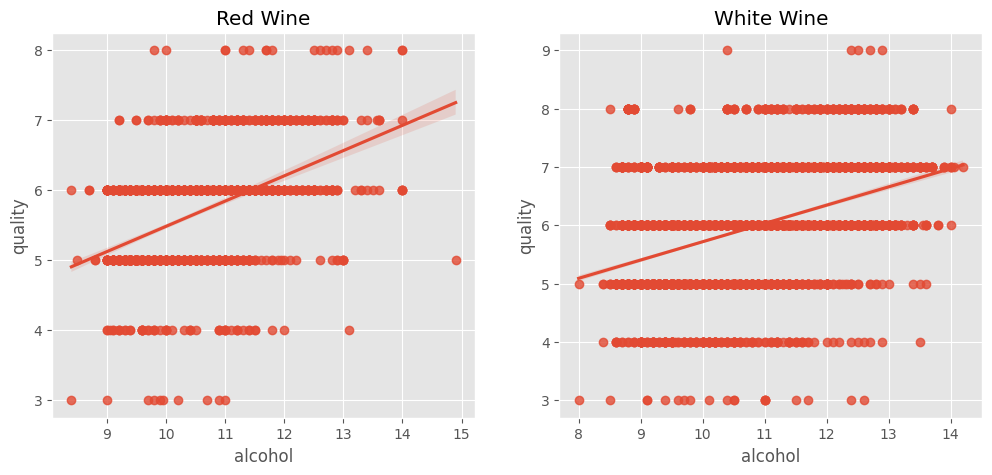

In [ ]:
plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
sns.regplot(x="alcohol", y="quality", data=red)
plt.title("Red Wine")

plt.subplot(1,2,2)
sns.regplot(x="alcohol", y="quality", data=white)
plt.title("White Wine")

plt.show()

##Question 22

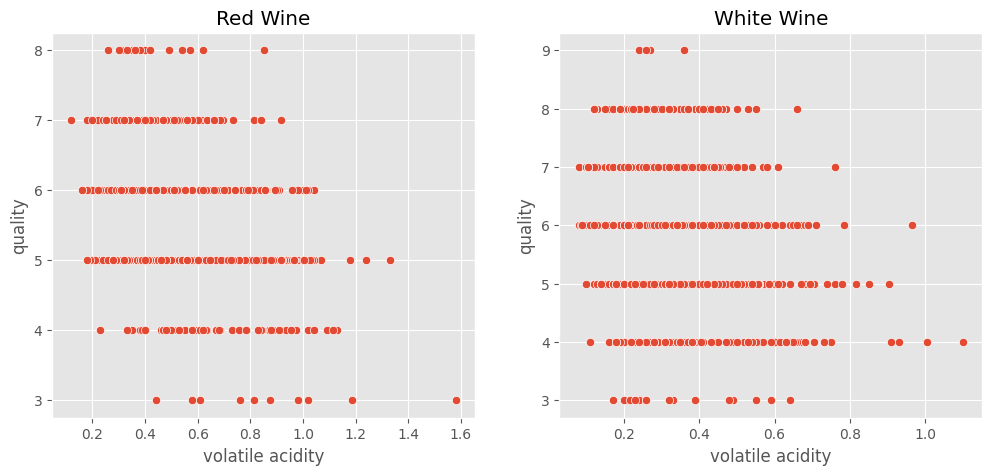

In [ ]:
plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
sns.scatterplot(x="volatile acidity", y="quality", data=red)
plt.title("Red Wine")

plt.subplot(1,2,2)
sns.scatterplot(x="volatile acidity", y="quality", data=white)
plt.title("White Wine")

plt.show()

##Question 23

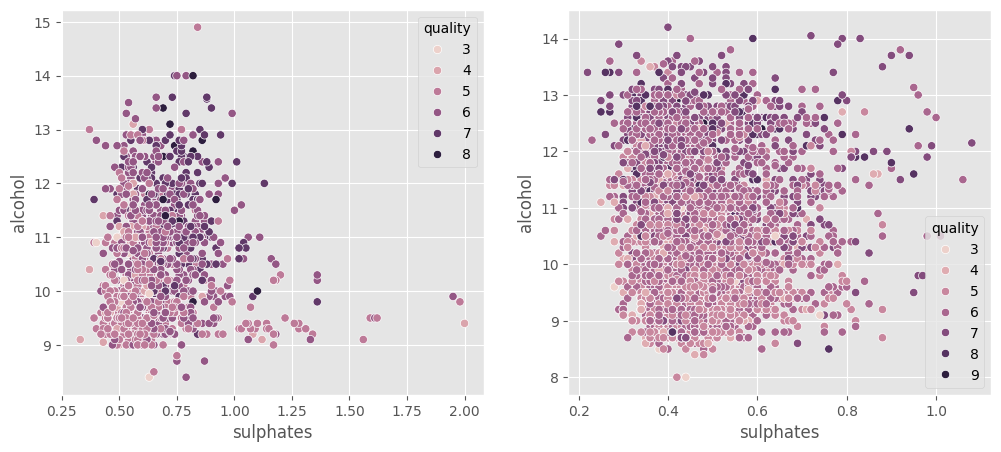

In [ ]:
plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
sns.scatterplot(x="sulphates", y="alcohol", hue="quality", data=red)

plt.subplot(1,2,2)
sns.scatterplot(x="sulphates", y="alcohol", hue="quality", data=white)

plt.show()

##Question 24

In [ ]:
from scipy.stats import pearsonr, spearmanr

print("Red Wine")
print("Pearson:", pearsonr(red["alcohol"], red["quality"]))
print("Spearman:", spearmanr(red["alcohol"], red["quality"]))

print("\nWhite Wine")
print("Pearson:", pearsonr(white["alcohol"], white["quality"]))
print("Spearman:", spearmanr(white["alcohol"], white["quality"]))

Red Wine
Pearson: PearsonRResult(statistic=np.float64(0.47616632400113607), pvalue=np.float64(2.831476974776179e-91))
Spearman: SignificanceResult(statistic=np.float64(0.47853168747024344), pvalue=np.float64(2.7268377398474203e-92))

White Wine
Pearson: PearsonRResult(statistic=np.float64(0.4355747154613733), pvalue=np.float64(5.6147702537305884e-226))
Spearman: SignificanceResult(statistic=np.float64(0.44036918162468297), pvalue=np.float64(1.6591955335864813e-231))


##Question 25

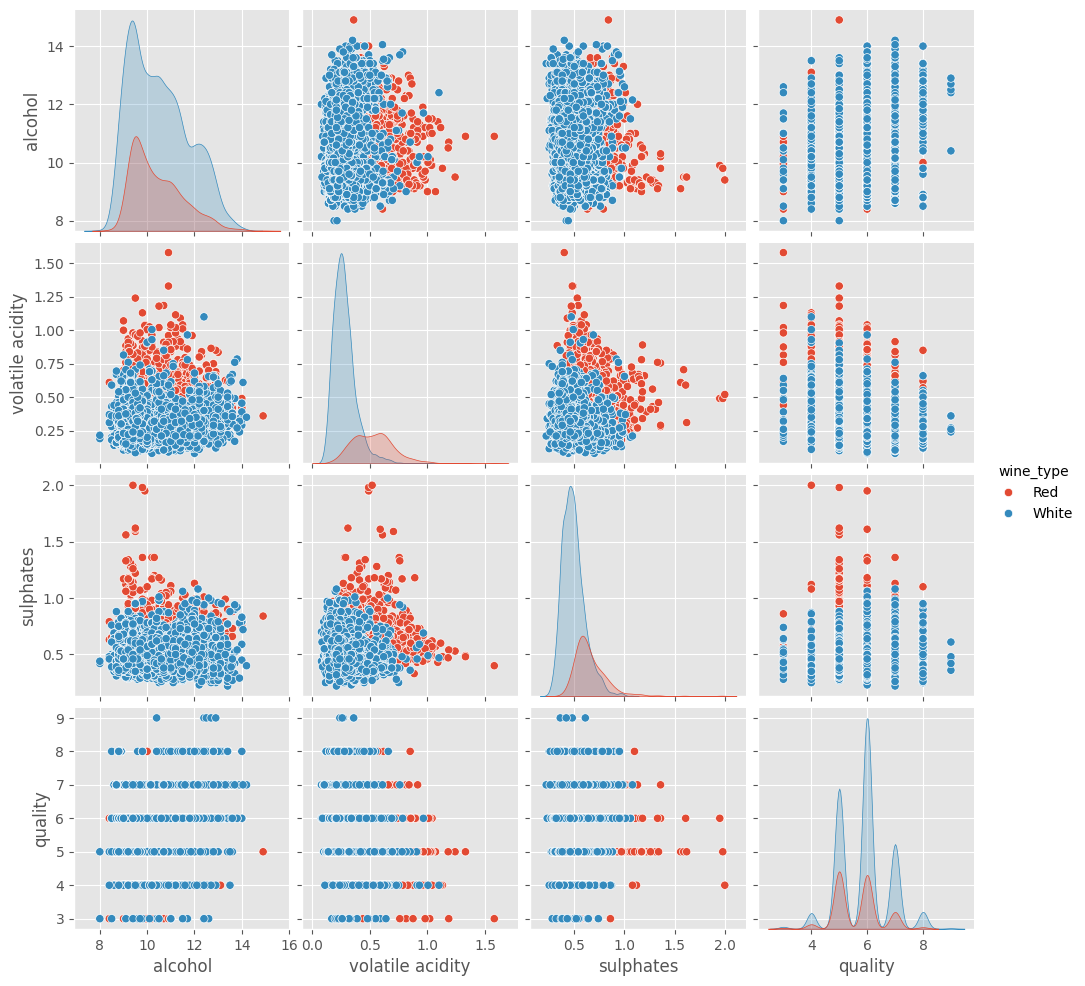

In [ ]:
wine = pd.concat([red, white], ignore_index=True)

sns.pairplot(
    wine,
    vars=["alcohol", "volatile acidity", "sulphates", "quality"],
    hue="wine_type"
)

plt.show()

#SECTION E

##Question 26

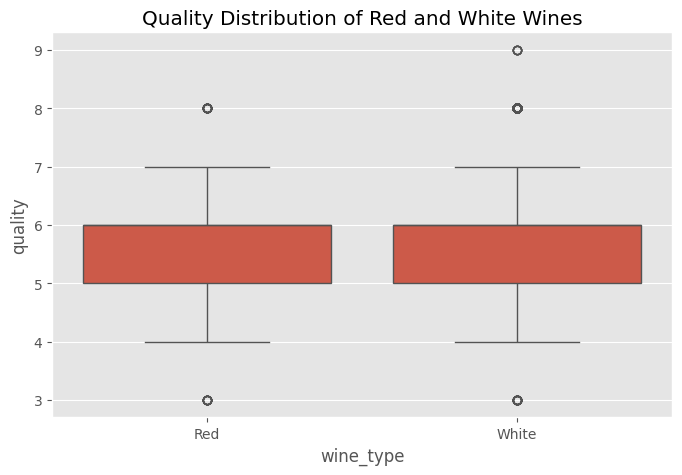

In [ ]:
plt.figure(figsize=(8,5))

sns.boxplot(x="wine_type", y="quality", data=wine)

plt.title("Quality Distribution of Red and White Wines")
plt.show()

#Question 27

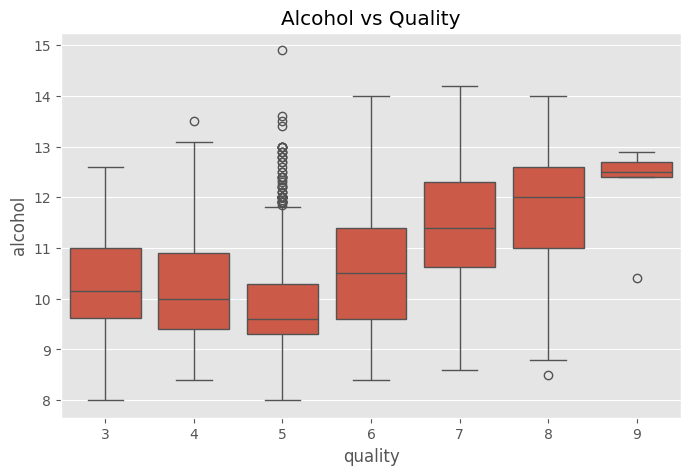

In [ ]:
plt.figure(figsize=(8,5))

sns.boxplot(x="quality", y="alcohol", data=wine)

plt.title("Alcohol vs Quality")
plt.show()

#Question 28

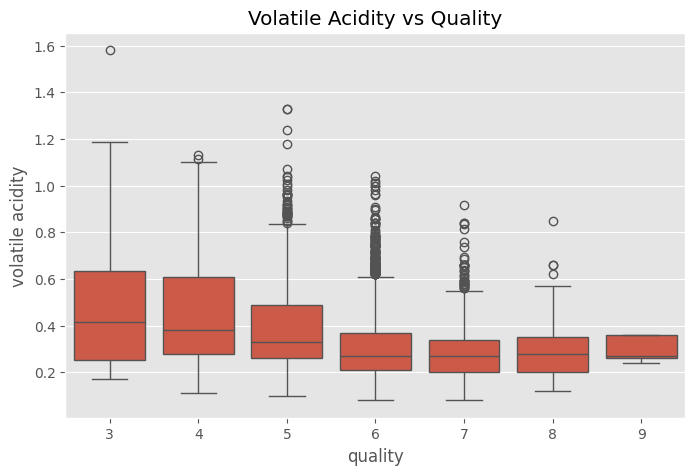

In [ ]:
plt.figure(figsize=(8,5))

sns.boxplot(x="quality", y="volatile acidity", data=wine)

plt.title("Volatile Acidity vs Quality")
plt.show()

#Question 29

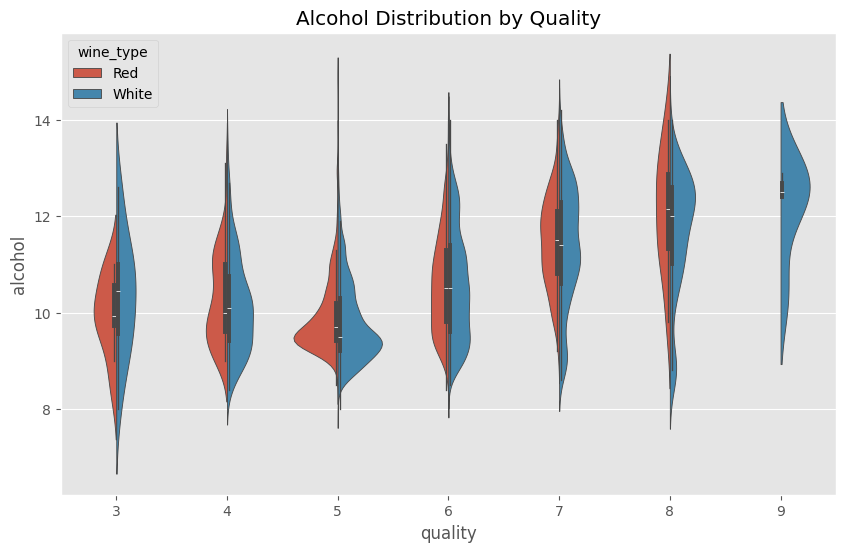

In [ ]:
plt.figure(figsize=(10,6))

sns.violinplot(x="quality",
               y="alcohol",
               hue="wine_type",
               data=wine,
               split=True)

plt.title("Alcohol Distribution by Quality")
plt.show()

##Question 30

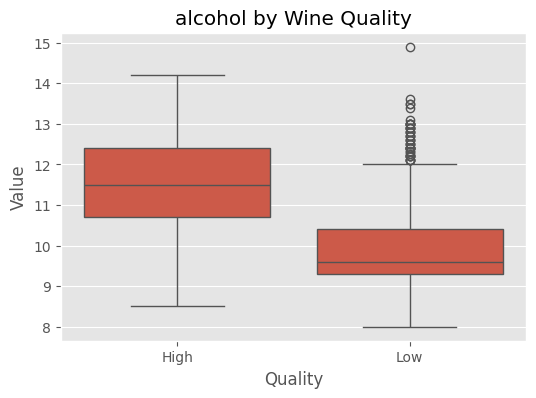

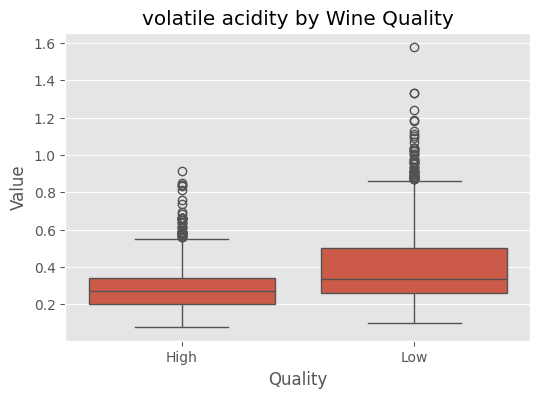

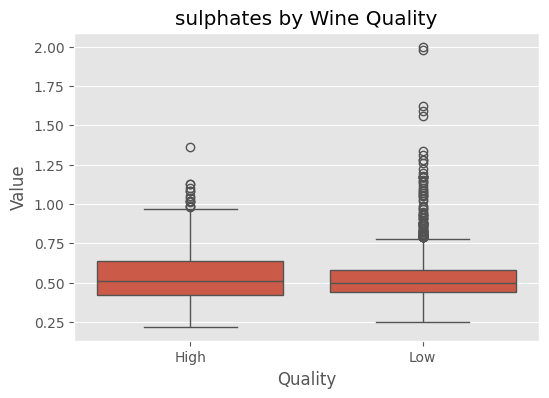

In [ ]:
high_quality = wine[wine["quality"] >= 7]
low_quality = wine[wine["quality"] <= 5]

features = ["alcohol", "volatile acidity", "sulphates"]

for feature in features:
    plot_data = pd.DataFrame({
        "Value": pd.concat(
            [high_quality[feature], low_quality[feature]],
            ignore_index=True
        ),
        "Quality": ["High"] * len(high_quality) + ["Low"] * len(low_quality)
    })

    plt.figure(figsize=(6,4))
    sns.boxplot(x="Quality", y="Value", data=plot_data)
    plt.title(f"{feature} by Wine Quality")
    plt.show()

#SECTION F

##Question 31

In [ ]:
numeric_columns = wine.select_dtypes(include=np.number).columns

for col in numeric_columns:
    Q1 = wine[col].quantile(0.25)
    Q3 = wine[col].quantile(0.75)
    IQR = Q3 - Q1

    outliers = wine[(wine[col] < Q1 - 1.5*IQR) | (wine[col] > Q3 + 1.5*IQR)]

    print(col, ":", len(outliers))

fixed acidity : 357
volatile acidity : 377
citric acid : 509
residual sugar : 118
chlorides : 286
free sulfur dioxide : 62
total sulfur dioxide : 10
density : 3
pH : 73
sulphates : 191
alcohol : 3
quality : 228


##Question 32

In [ ]:
from scipy.stats import zscore

z_scores = np.abs(zscore(wine.select_dtypes(include=np.number)))

outliers = (z_scores > 3).sum(axis=0)

for col, count in zip(wine.select_dtypes(include=np.number).columns, outliers):
    print(col, ":", count)

fixed acidity : 128
volatile acidity : 95
citric acid : 28
residual sugar : 26
chlorides : 107
free sulfur dioxide : 36
total sulfur dioxide : 8
density : 3
pH : 33
sulphates : 75
alcohol : 2
quality : 35


##Question 33

In [ ]:
from scipy.stats import ttest_ind

t_stat, p_value = ttest_ind(red["alcohol"], white["alcohol"])

print("T-Statistic:", t_stat)
print("P-value:", p_value)

T-Statistic: -2.6585128987466375
P-value: 0.007867873993342453


##Question 34

In [ ]:
from scipy.stats import mannwhitneyu

u_stat, p_value = mannwhitneyu(red["quality"], white["quality"])

print("U Statistic:", u_stat)
print("P-value:", p_value)

U Statistic: 3311514.0
P-value: 3.6343410707988e-23


##Question 35

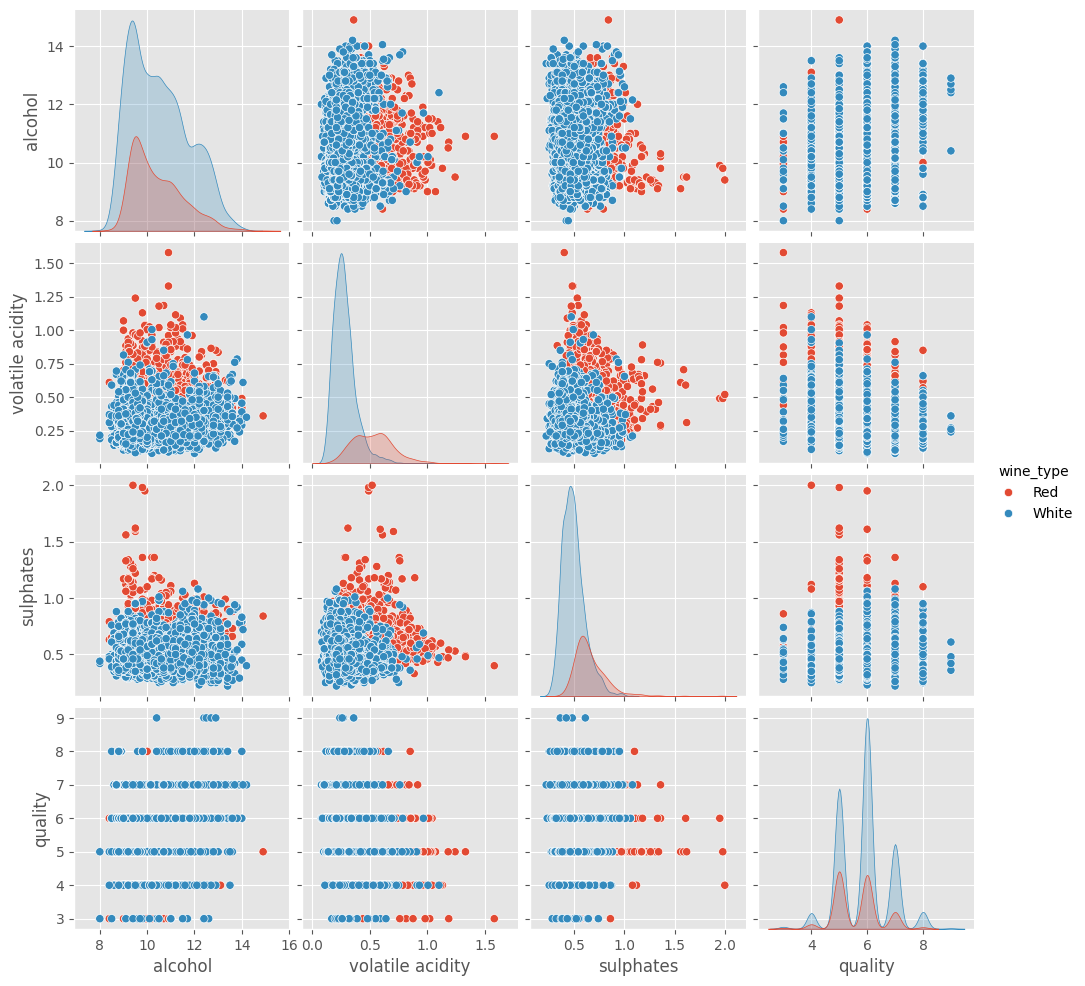

In [ ]:
sns.pairplot(
    wine,
    vars=["alcohol", "volatile acidity", "sulphates", "quality"],
    hue="wine_type"
)

plt.show()

#B1

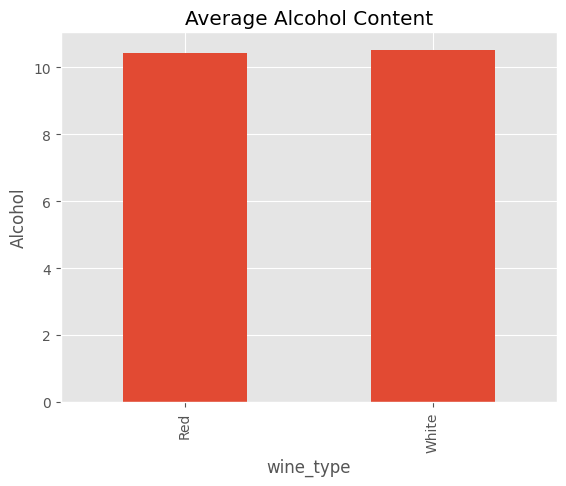

In [ ]:
avg_alcohol = wine.groupby("wine_type")["alcohol"].mean()

avg_alcohol.plot(kind="bar")
plt.title("Average Alcohol Content")
plt.ylabel("Alcohol")
plt.show()

#B2

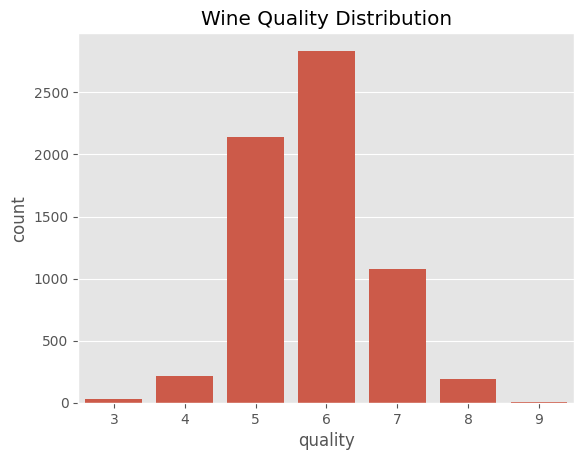

In [ ]:
sns.countplot(x="quality", data=wine)

plt.title("Wine Quality Distribution")
plt.show()

#B3

In [ ]:
print(wine.groupby("wine_type")["quality"].mean())

wine_type
Red      5.636023
White    5.877909
Name: quality, dtype: float64


#B4

In [ ]:
corr = wine.corr(numeric_only=True)["quality"].sort_values(ascending=False)

print(corr)

quality                 1.000000
alcohol                 0.444319
citric acid             0.085532
free sulfur dioxide     0.055463
sulphates               0.038485
pH                      0.019506
residual sugar         -0.036980
total sulfur dioxide   -0.041385
fixed acidity          -0.076743
chlorides              -0.200666
volatile acidity       -0.265699
density                -0.305858
Name: quality, dtype: float64


#B5

In [ ]:
corr = wine.corr(numeric_only=True)["quality"].sort_values()

print(corr)

density                -0.305858
volatile acidity       -0.265699
chlorides              -0.200666
fixed acidity          -0.076743
total sulfur dioxide   -0.041385
residual sugar         -0.036980
pH                      0.019506
sulphates               0.038485
free sulfur dioxide     0.055463
citric acid             0.085532
alcohol                 0.444319
quality                 1.000000
Name: quality, dtype: float64


#B6

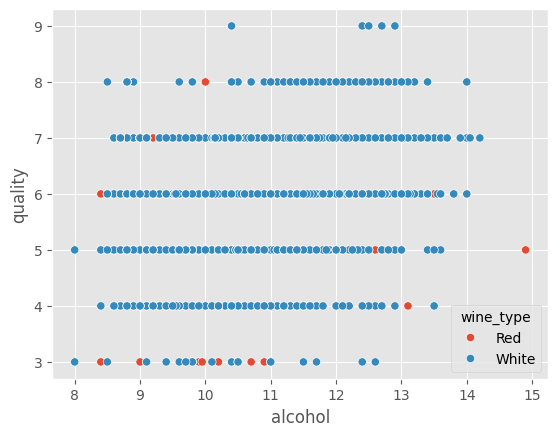

In [ ]:
sns.scatterplot(
    x="alcohol",
    y="quality",
    hue="wine_type",
    data=wine
)

plt.show()

#B7

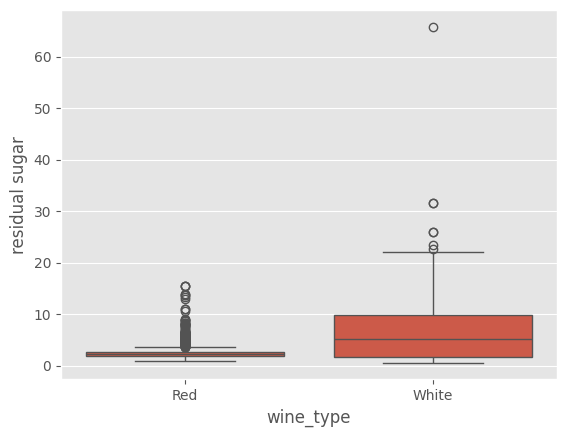

In [ ]:
sns.boxplot(
    x="wine_type",
    y="residual sugar",
    data=wine
)

plt.show()

#B8

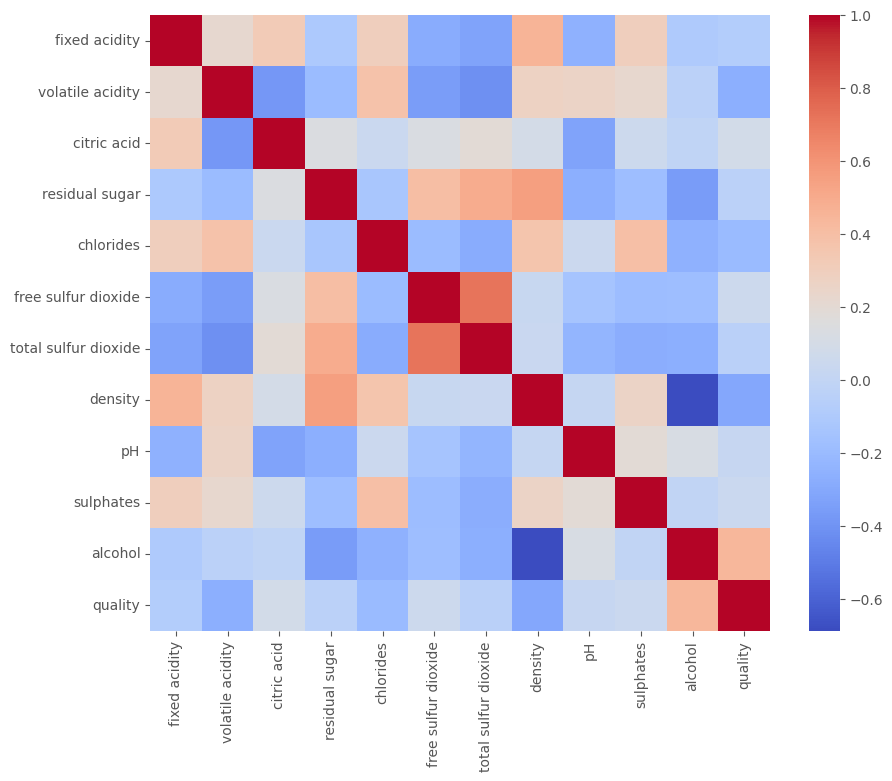

In [ ]:
plt.figure(figsize=(10,8))

sns.heatmap(
    wine.corr(numeric_only=True),
    cmap="coolwarm"
)

plt.show()

#B9

In [ ]:
wine.sort_values(
    by="alcohol",
    ascending=False
).head(10)

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,wine_type
652,15.9,0.360,0.65,7.5,0.096,22.0,71.0,0.99760,2.98,0.84,14.90,5,Red
5517,6.4,0.350,0.28,1.6,0.037,31.0,113.0,0.98779,3.12,0.40,14.20,7,White
6102,5.8,0.610,0.01,8.4,0.041,31.0,104.0,0.99090,3.26,0.72,14.05,7,White
467,8.8,0.460,0.45,2.6,0.065,7.0,18.0,0.99470,3.32,0.79,14.00,6,Red
142,5.2,0.340,0.00,1.8,0.050,27.0,63.0,0.99160,3.68,0.79,14.00,6,Red
4749,5.8,0.390,0.47,7.5,0.027,12.0,88.0,0.99070,3.38,0.45,14.00,6,White
588,5.0,0.420,0.24,2.0,0.060,19.0,50.0,0.99170,3.72,0.74,14.00,8,Red
5503,5.0,0.455,0.18,1.9,0.036,33.0,106.0,0.98746,3.21,0.83,14.00,7,White
1269,5.5,0.490,0.03,1.8,0.044,28.0,87.0,0.99080,3.50,0.82,14.00,8,Red
1270,5.0,0.380,0.01,1.6,0.048,26.0,60.0,0.99084,3.70,0.75,14.00,6,Red


#B10

Conclusion:
The Wine Quality dataset was successfully analyzed using Exploratory Data Analysis (EDA). Red and white wines differ in several physicochemical properties such as alcohol content, volatile acidity, density, and sulphates. Alcohol showed a positive relationship with wine quality, while volatile acidity had a negative relationship. Correlation analysis, statistical tests, and visualizations helped identify important factors influencing wine quality.